# Netflix-Style Subscriber Churn and Engagement Analysis

Author: Robin Christian Navarro <br>
Date: November 10, 2026


## Exploratory Data Analysis

### Introduction

A streaming retention team wants to know which subscriber segments show the strongest association with the churn label. We will compare subscription plans, regions, devices, and engagement to identify a segment worth investigating.

The CSV has no observation dates or verified event sequence. This project uses the data as a Netflix-style case study. Its churn percentages describe the share labeled as churned in the sample.

**Source.** [Netflix Customer Churn & Engagement Analytics on Kaggle](https://www.kaggle.com/datasets/zeyadmohamed26/netflix-customer-churn-and-engagement-analytics)

#### Business Questions

1. How many subscribers are labeled as churned or retained, and what percentage is labeled as churned?
2. Which subscription plans have the highest churn proportions and largest churned counts?
3. How does the churn proportion vary by days since last login?
4. How does average daily watch time differ between churned and retained subscribers?
5. How large are the differences across regions, and how many subscribers support each comparison?
6. Within the same subscription plan, how does the churn proportion vary by device?
7. Is the churn proportion higher when subscribers show both lower viewing and less recent login?

---

### Environment Setup

We will import the necessary libraries and load the dataset for analysis.
- Pandas - for data manipulation and analysis
- Matplotlib and Seaborn - for data visualization

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Read the dataset
df = pd.read_csv("./data/raw/netflix_customer_churn.csv")

--- 

### Data Exploration

In [3]:
# Preview the first few rows without the subscriber identifier
df.drop(columns='customer_id').head()

,age,gender,subscription_type,watch_hours,last_login_days,region,device,monthly_fee,churned,payment_method,number_of_profiles,avg_watch_time_per_day,favorite_genre
0,51,Other,Basic,14.73,29,Africa,TV,8.99,1,Gift Card,1,0.49,Action
1,47,Other,Standard,0.70,19,Europe,Mobile,13.99,1,Gift Card,5,0.03,Sci-Fi
2,27,Female,Standard,16.32,10,Asia,TV,13.99,0,Crypto,2,1.48,Drama
3,53,Other,Premium,4.51,12,Oceania,TV,17.99,1,Crypto,2,0.35,Horror
4,56,Other,Standard,1.89,13,Africa,Mobile,13.99,1,Crypto,2,0.13,Action


In [4]:
# Preview the last few rows without the subscriber identifier
df.drop(columns='customer_id').tail()

,age,gender,subscription_type,watch_hours,last_login_days,region,device,monthly_fee,churned,payment_method,number_of_profiles,avg_watch_time_per_day,favorite_genre
4995,19,Female,Basic,49.17,11,Europe,Desktop,8.99,0,Credit Card,4,4.10,Drama
4996,67,Female,Basic,9.24,2,North America,Desktop,8.99,0,PayPal,3,3.08,Documentary
4997,66,Male,Standard,16.55,49,South America,Desktop,13.99,1,Debit Card,2,0.33,Action
4998,59,Female,Basic,9.12,3,Europe,Laptop,8.99,0,Credit Card,4,2.28,Sci-Fi
4999,57,Male,Basic,1.62,17,Africa,Mobile,8.99,1,Crypto,2,0.09,Action


In [5]:
# The shape of the dataset
rows, columns = df.shape
print(f"The dataset contains {rows} rows and {columns} columns.")

The dataset contains 5000 rows and 14 columns.


In [6]:
# Information about the dataset
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   customer_id             5000 non-null   str    
 1   age                     5000 non-null   int64  
 2   gender                  5000 non-null   str    
 3   subscription_type       5000 non-null   str    
 4   watch_hours             5000 non-null   float64
 5   last_login_days         5000 non-null   int64  
 6   region                  5000 non-null   str    
 7   device                  5000 non-null   str    
 8   monthly_fee             5000 non-null   float64
 9   churned                 5000 non-null   int64  
 10  payment_method          5000 non-null   str    
 11  number_of_profiles      5000 non-null   int64  
 12  avg_watch_time_per_day  5000 non-null   float64
 13  favorite_genre          5000 non-null   str    
dtypes: float64(3), int64(4), str(7)
memory usage: 547.0

---

### Data Cleaning

In [7]:
# Check for missing values
df.isnull().sum()

customer_id               0
age                       0
gender                    0
subscription_type         0
watch_hours               0
last_login_days           0
region                    0
device                    0
monthly_fee               0
churned                   0
payment_method            0
number_of_profiles        0
avg_watch_time_per_day    0
favorite_genre            0
dtype: int64

The result shows that there are no missing values in the dataset.

In [8]:
# Check for duplicate rows and repeated subscriber IDs
print(f"Duplicate rows: {df.duplicated().sum()}")
print(f"Repeated subscriber IDs: {df['customer_id'].duplicated().sum()}")

Duplicate rows: 0
Repeated subscriber IDs: 0


There are no duplicate rows or repeated subscriber IDs. Each row represents one subscriber record.

In [9]:
# Check outcome labels and valid ranges for engagement
assert df['churned'].isin([0, 1]).all()
assert df['last_login_days'].ge(0).all()
valid_watch_time = df['avg_watch_time_per_day'].between(0, 24)
watch_df = df.loc[valid_watch_time].copy()
print(f"Daily watch time outside 0–24 hours: {(~valid_watch_time).sum()}")

Daily watch time outside 0–24 hours: 10


Ten retained subscribers have values above 24 hours per day. Questions 4 and 7 use the 4,990 valid watch-time records. All 5,000 subscribers remain in analyses that do not use this field.

---

### Descriptive Statistics

In [10]:
df.describe(include='all')

,customer_id,age,gender,subscription_type,watch_hours,last_login_days,region,device,monthly_fee,churned,payment_method,number_of_profiles,avg_watch_time_per_day,favorite_genre
count,5000,5000.000000,5000,5000,5000.000000,5000.000000,5000,5000,5000.000000,5000.000000,5000,5000.000000,5000.000000,5000
unique,5000,NaN,3,3,NaN,NaN,6,5,NaN,NaN,5,NaN,NaN,7
top,a9b75100-82a8-427a-a208-72f24052884a,NaN,Female,Premium,NaN,NaN,South America,Tablet,NaN,NaN,Debit Card,NaN,NaN,Drama
freq,1,NaN,1711,1693,NaN,NaN,873,1048,NaN,NaN,1030,NaN,NaN,731
mean,NaN,43.847400,NaN,NaN,11.649450,30.089800,NaN,NaN,13.683400,0.503000,NaN,3.024400,0.874800,NaN
std,NaN,15.501128,NaN,NaN,12.014654,17.536078,NaN,NaN,3.692062,0.500041,NaN,1.415841,2.619824,NaN
min,NaN,18.000000,NaN,NaN,0.010000,0.000000,NaN,NaN,8.990000,0.000000,NaN,1.000000,0.000000,NaN
25%,NaN,30.000000,NaN,NaN,3.337500,15.000000,NaN,NaN,8.990000,0.000000,NaN,2.000000,0.110000,NaN
50%,NaN,44.000000,NaN,NaN,8.000000,30.000000,NaN,NaN,13.990000,1.000000,NaN,3.000000,0.290000,NaN
75%,NaN,58.000000,NaN,NaN,16.030000,45.000000,NaN,NaN,17.990000,1.000000,NaN,4.000000,0.720000,NaN


---

### Exploratory Data Analysis

#### 1. How many subscribers are labeled as churned or retained, and what percentage of the dataset is labeled as churned?

In [11]:
# Count and label the churn outcomes before plotting
churned_counts = df['churned'].value_counts().reindex([0, 1], fill_value=0)
churned_percentage = churned_counts / churned_counts.sum() * 100
churned_summary = pd.DataFrame({
    'Count': churned_counts,
    'Percentage': churned_percentage
})
churned_summary.index = pd.Index(['Retained', 'Churned'], name='Churn Status')
churned_summary.round(1)

,Count,Percentage
Churn Status,,
Retained,2485,49.7
Churned,2515,50.3


**Result.** The dataset contains 2,515 churned subscribers (50.3%) and 2,485 retained subscribers (49.7%). The 50.3% share is the reference for the group comparisons below.

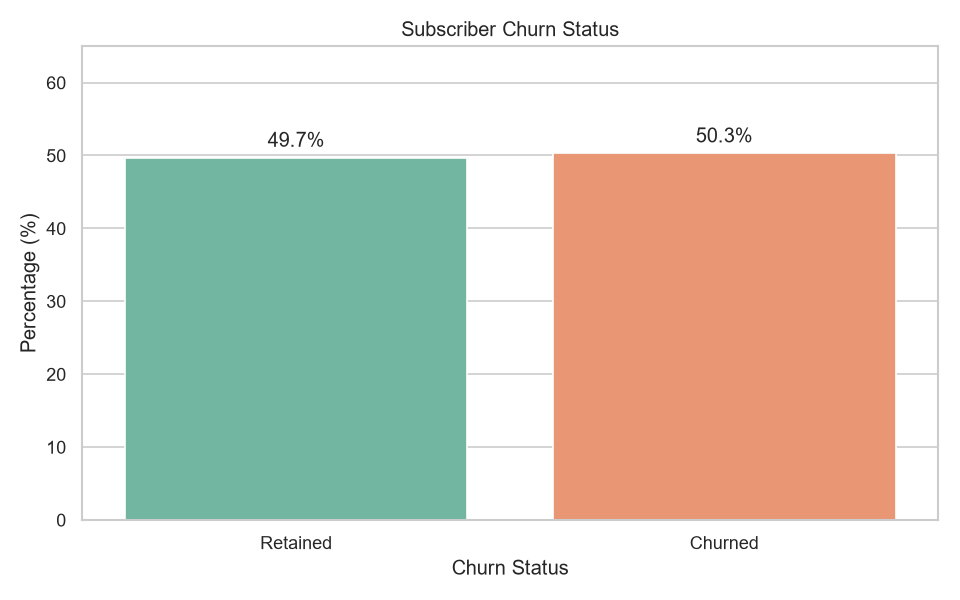

In [12]:
# Set theme
sns.set_theme(style="whitegrid")

# Create figure
figure, axis = plt.subplots(1, 1, figsize=(8, 5))

# Plot percentage barplot
churned_graph = sns.barplot(
    data=churned_summary.reset_index(),
    x='Churn Status',
    y='Percentage',
    hue='Churn Status',
    palette="Set2",
    legend=False,
    ax=axis
)

# Set title and labels
churned_graph.set(
    title='Subscriber Churn Status',
    xlabel='Churn Status',
    ylabel='Percentage (%)',
    ylim=(0, 65)
)
axis.bar_label(axis.containers[0], fmt='%.1f%%', padding=4)
axis.bar_label(axis.containers[1], fmt='%.1f%%', padding=4)

# Set spacing
figure.tight_layout()
plt.show()

#### 2. Which subscription plans have the highest churn proportions, and which account for the largest number of churned subscribers?

In [13]:
# Compare plan churn counts and percentages using each plan's subscriber count
subscription_churn_summary = df.groupby('subscription_type')['churned'].agg(
    Subscription_Count='size',
    Churned_Count='sum'
)
subscription_churn_summary['Churned_Percentage'] = (
    subscription_churn_summary['Churned_Count'] / subscription_churn_summary['Subscription_Count'] * 100
)
subscription_churn_summary = subscription_churn_summary.sort_values(by='Churned_Count', ascending=False)
subscription_churn_summary.round(1)

,Subscription_Count,Churned_Count,Churned_Percentage
subscription_type,,,
Basic,1661,1027,61.8
Standard,1646,748,45.4
Premium,1693,740,43.7


**Result.** Basic has both the highest share labeled as churned (61.8%, 1,027 of 1,661) and the largest churned count. Standard is at 45.4% and Premium at 43.7%. Basic is the first plan to investigate because it leads on both measures.

#### 3. How does the churn proportion vary by days since last login?

In [14]:
# Group subscribers by days since last login
login_groups = ['0–14', '15–29', '30–44', '45+']
df['Login Group'] = pd.cut(
    df['last_login_days'],
    bins=[0, 15, 30, 45, float('inf')],
    labels=login_groups,
    right=False
)
login_churn_summary = df.groupby('Login Group', observed=True)['churned'].agg(
    Subscriber_Count='size',
    Churned_Count='sum'
)
login_churn_summary['Churned_Percentage'] = (
    login_churn_summary['Churned_Count'] / login_churn_summary['Subscriber_Count'] * 100
)
login_churn_summary.round(1)

,Subscriber_Count,Churned_Count,Churned_Percentage
Login Group,,,
0–14,1209,238,19.7
15–29,1236,390,31.6
30–44,1244,891,71.6
45+,1311,996,76.0


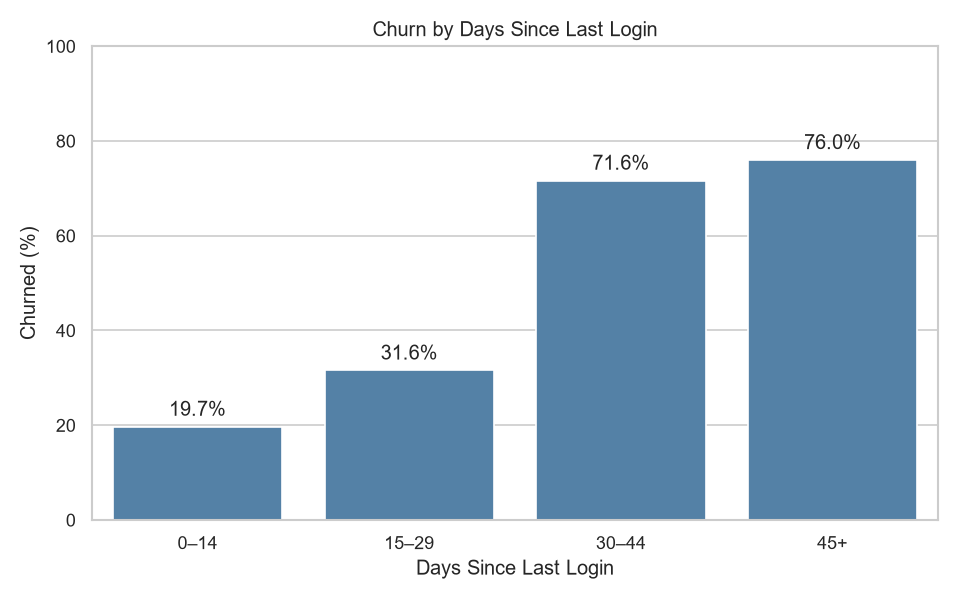

In [15]:
# Plot the churn percentage for each login group
figure, axis = plt.subplots(1, 1, figsize=(8, 5))
login_graph = sns.barplot(
    data=login_churn_summary.reset_index(),
    x='Login Group',
    y='Churned_Percentage',
    color='steelblue',
    ax=axis
)
login_graph.set(title='Churn by Days Since Last Login', xlabel='Days Since Last Login',
                ylabel='Churned (%)', ylim=(0, 100))
axis.bar_label(axis.containers[0], fmt='%.1f%%', padding=4)
figure.tight_layout()
plt.show()

**Result.** The share labeled as churned rises from 19.7% for 0–14 days (238 of 1,209) to 76.0% for 45+ days (996 of 1,311). The largest step is between 15–29 days (31.6%) and 30–44 days (71.6%).

#### 4. How does average daily watch time differ between churned and retained subscribers?

In [16]:
# Compare the middle half of daily watch time by churn status
watch_df['Churn Status'] = watch_df['churned'].map({0: 'Retained', 1: 'Churned'})
watch_time = watch_df.groupby('Churn Status')['avg_watch_time_per_day']
watch_summary = watch_time.agg(Subscriber_Count='size', Median_Hours='median')
watch_summary['Q1_Hours'] = watch_time.quantile(0.25)
watch_summary['Q3_Hours'] = watch_time.quantile(0.75)
watch_summary.round(2)

,Subscriber_Count,Median_Hours,Q1_Hours,Q3_Hours
Churn Status,,,,
Churned,2515,0.12,0.06,0.23
Retained,2475,0.72,0.40,1.44


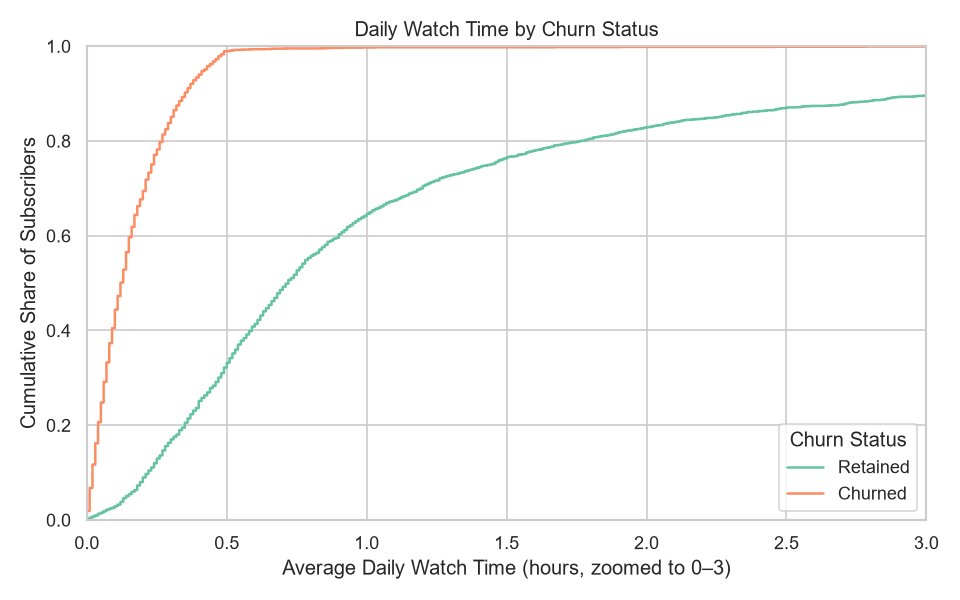

In [17]:
# Compare cumulative distributions and zoom in on the first three hours
figure, axis = plt.subplots(1, 1, figsize=(8, 5))
watch_graph = sns.ecdfplot(
    data=watch_df,
    x='avg_watch_time_per_day',
    hue='Churn Status',
    hue_order=['Retained', 'Churned'],
    palette='Set2',
    ax=axis
)
watch_graph.set(
    title='Daily Watch Time by Churn Status',
    xlabel='Average Daily Watch Time (hours, zoomed to 0–3)',
    ylabel='Cumulative Share of Subscribers',
    xlim=(0, 3)
)
figure.tight_layout()
plt.show()

**Result.** Among valid records, the median is 0.12 hours per day for churned subscribers and 0.72 hours for retained subscribers. The middle half is 0.06–0.23 hours for churned subscribers versus 0.40–1.44 hours for retained subscribers. The chart zooms in on the first three hours and the calculations include all valid values.

#### 5. How large are the differences across regions, and how many subscribers support each comparison?

In [18]:
# Compare regional churn proportions alongside their denominators
region_churn_summary = df.groupby('region')['churned'].agg(
    Subscriber_Count='size',
    Churned_Count='sum'
)
region_churn_summary['Churned_Percentage'] = (
    region_churn_summary['Churned_Count'] / region_churn_summary['Subscriber_Count'] * 100
)
region_churn_summary.sort_values(by='Churned_Percentage', ascending=False).round(1)

,Subscriber_Count,Churned_Count,Churned_Percentage
region,,,
Europe,867,448,51.7
South America,873,449,51.4
Asia,841,426,50.7
Oceania,765,383,50.1
North America,851,421,49.5
Africa,803,388,48.3


**Result.** Europe has the highest observed share at 51.7% (448 of 867), and Africa has the lowest at 48.3% (388 of 803). The spread is 3.4 percentage points. This is small compared with the differences across engagement groups in this sample.

#### 6. Within the same subscription plan, how does the churn proportion vary by device?

In [19]:
# Group by plan and device so each rate uses its own segment count
device_churn_summary = df.groupby(['subscription_type', 'device'])['churned'].agg(
    Subscriber_Count='size',
    Churned_Count='sum'
)
device_churn_summary['Churned_Percentage'] = (
    device_churn_summary['Churned_Count'] / device_churn_summary['Subscriber_Count'] * 100
)
device_churn_summary.round(1)

Subscriber_Count  Churned_Count  Churned_Percentage
subscription_type device                                                      
Basic             Desktop               286            177                61.9
                  Laptop                327            215                65.7
                  Mobile                342            208                60.8
                  TV                    349            204                58.5
                  Tablet                357            223                62.5
Premium           Desktop               341            145                42.5
                  Laptop                329            136                41.3
                  Mobile                332            155                46.7
                  TV                    338            152                45.0
                  Tablet                353            152                43.1
Standard          Desktop               322            145                45.0
                  Laptop                350            170                48.6
                  Mobile                330            144                43.6
                  TV                    306            140                45.8
                  Tablet                338            149                44.1

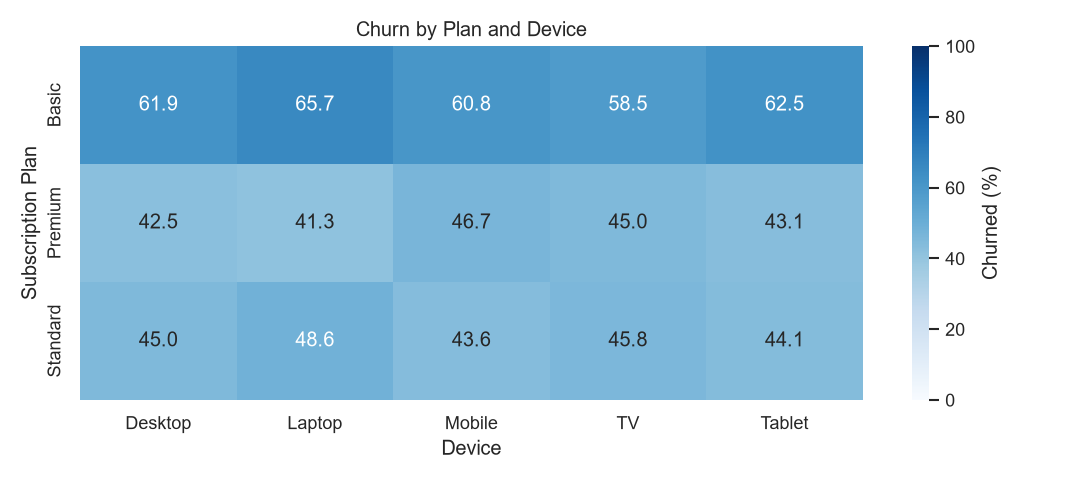

In [20]:
# Show device churn percentages side by side within each plan
device_churn_grid = device_churn_summary['Churned_Percentage'].unstack()
figure, axis = plt.subplots(1, 1, figsize=(9, 4))
device_graph = sns.heatmap(
    device_churn_grid,
    annot=True,
    fmt='.1f',
    cmap='Blues',
    vmin=0,
    vmax=100,
    cbar_kws={'label': 'Churned (%)'},
    ax=axis
)
device_graph.set(title='Churn by Plan and Device', xlabel='Device', ylabel='Subscription Plan')
figure.tight_layout()
plt.show()

**Result.** Basic has the highest observed churn proportion within every device category. Laptop leads in Basic (65.7%, 215 of 327) and Standard (48.6%, 170 of 350), while Mobile leads in Premium (46.7%, 155 of 332). A single device category does not lead across all plans.

#### 7. Is the churn proportion higher when subscribers show both lower viewing and less recent login?

For this comparison, low viewing means fewer than 0.30 hours per day (18 minutes), and less recent login means at least 30 days since last login. These thresholds define four comparison groups in this sample.

In [21]:
# Combine the two engagement signals
watch_df['Low Watch'] = watch_df['avg_watch_time_per_day'].lt(0.30)
watch_df['Less Recent Login'] = watch_df['last_login_days'].ge(30)
watch_df['Engagement Group'] = 'Neither signal'
watch_df.loc[watch_df['Low Watch'], 'Engagement Group'] = 'Low watch only'
watch_df.loc[watch_df['Less Recent Login'], 'Engagement Group'] = 'Less recent login only'
watch_df.loc[watch_df['Low Watch'] & watch_df['Less Recent Login'], 'Engagement Group'] = 'Both signals'

engagement_churn_summary = watch_df.groupby('Engagement Group')['churned'].agg(
    Subscriber_Count='size',
    Churned_Count='sum'
)
engagement_churn_summary['Churned_Percentage'] = (
    engagement_churn_summary['Churned_Count'] / engagement_churn_summary['Subscriber_Count'] * 100
)
engagement_churn_summary = engagement_churn_summary.sort_values('Churned_Percentage', ascending=False)
engagement_churn_summary.round(1)

,Subscriber_Count,Churned_Count,Churned_Percentage
Engagement Group,,,
Both signals,1744,1596,91.5
Low watch only,766,511,66.7
Less recent login only,811,291,35.9
Neither signal,1669,117,7.0


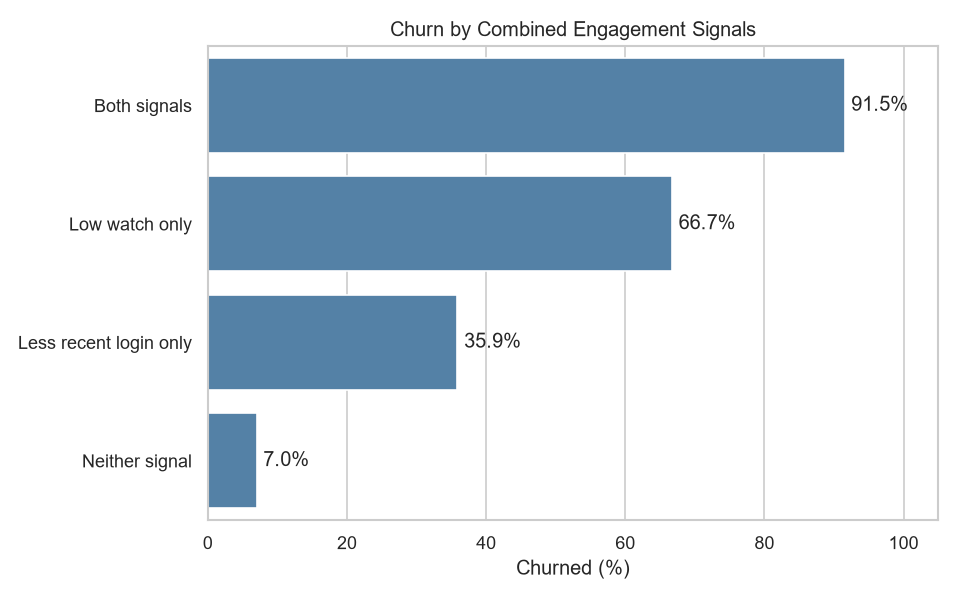

In [22]:
# Plot each engagement group's observed churn percentage
figure, axis = plt.subplots(1, 1, figsize=(8, 5))
engagement_graph = sns.barplot(
    data=engagement_churn_summary.reset_index(),
    x='Churned_Percentage',
    y='Engagement Group',
    color='steelblue',
    ax=axis
)
engagement_graph.set(title='Churn by Combined Engagement Signals',
                     xlabel='Churned (%)', ylabel='', xlim=(0, 105))
axis.bar_label(axis.containers[0], fmt='%.1f%%', padding=4)
figure.tight_layout()
plt.show()

**Result.** Both signals appear together in 1,744 records, of which 1,596 are labeled as churned (91.5%). The share is 66.7% for low watch time alone (511 of 766), 35.9% for less recent login alone (291 of 811), and 7.0% for neither signal (117 of 1,669).

---

### Conclusion

**What the data shows.** Basic has the highest churn proportion (61.8%) and the most churned subscribers (1,027). Engagement gives the sharpest separation in the sample. Subscribers with both less recent login and low watch time show a 91.5% churn proportion, compared with 7.0% for subscribers with neither signal. Regional differences are smaller, and the leading device category varies by plan.

**What to do next.** Start with Basic when investigating retention and check whether the two engagement signals are recorded before cancellation. With dated events, define a fixed observation window, measure the signals before that window closes, and compare churn over the following period. If the pattern holds on a later cohort, test a re-engagement message against a control group before rolling it out.

**Limitations.** The dataset has no verified observation period or event sequence. These comparisons describe recorded labels, and the thresholds are exploratory. Ten invalid daily watch-time values were excluded only from the watch-time analyses.